In [1]:
import matplotlib.pyplot as plt
from granad import *
import numpy as np
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D

In [2]:
# Define flake and bulk (Periodic) structure 

# FLAKE
lattice_constant = 2.62 # Å
lattice_basis = [[1, 0, 0], [-0.5, jnp.sqrt(3)/2, 0]] 
au_s_hoppings = [-0.96, -1.14, 0.35]   # PARAMETERS TUNED MANUALLY TO FIT THE EXPECTED ENERGY BAND :)

goldene = (Material("Au")
        .lattice_constant(lattice_constant)
        .lattice_basis(lattice_basis)
        .add_orbital_species("s_gold", atom='Au')
        .add_orbital(position=(0, 0), tag="Au_s", species="s_gold")
        .add_interaction(
            "hamiltonian",
            participants=("s_gold", "s_gold"),
            parameters=au_s_hoppings,  
        )   )
flake = goldene.cut_flake(Rectangle(0.5, 0.5), minimum_neighbor_number = 0)

# BULK
lattice_vectors = lattice_constant*jnp.array([
    [1, 0, 0],
    [-0.5, jnp.sqrt(3)/2, 0] ])
fourier_cutoff = 4
bulk = Periodic(flake, lattice_vectors, fourier_cutoff)

In [3]:
N_monkhorst = 399

ks = bulk.get_kgrid_monkhorst_pack([N_monkhorst, N_monkhorst])
energies, vecs = bulk.get_eigenbasis(ks)
mu = bulk.get_mu(energies)
mu

Array(-0.65415215, dtype=float64)

Saving output file as goldene_-0.96_-1.14_mu-0.6542_acc0.03_N399.csv
0 of 159201
10000 of 159201
20000 of 159201
30000 of 159201
40000 of 159201
50000 of 159201
60000 of 159201
70000 of 159201
80000 of 159201
90000 of 159201
100000 of 159201
110000 of 159201
120000 of 159201
130000 of 159201
140000 of 159201
150000 of 159201


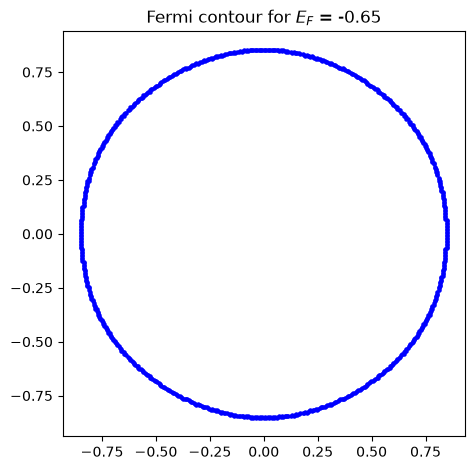

In [4]:
# Define parameters of the k-space sampling and Fermi contour search: 
# Monkhorst-Pack cell size, accuracy for Fermi contour search, Fermi level (mu)
N_monkhorst = 399
accuracy = 3e-2

# for mu in [-1, -0.6, 0]:

# Prepare output filename
filename = f"goldene_{au_s_hoppings[0]:.2f}_{au_s_hoppings[1]:.2f}_mu{mu:.4f}_acc{accuracy}_N{N_monkhorst}"
print(f"Saving output file as {filename}.csv")


# Iterate over points in k-space (Monkhorst-Pack cell) 
# and check for every point if it corresponds to Fermi energy (mu) within given accuracy

ks = bulk.get_kgrid_monkhorst_pack([N_monkhorst, N_monkhorst])
fermi_contour = []
fermi_energies = []
energy_band = []
a1 = lattice_vectors[0]
a2 = lattice_vectors[1]

# with open(f"../../outputs/fermi_contours/{filename}.csv", "w") as output_file:
for idx, coordinates in enumerate(ks.T):
    if not idx % 10000:
        print(f"{idx} of {len(ks.T)}")
    kx, ky, kz = coordinates
    energy = (2 * au_s_hoppings[1] * (
        np.cos(kx * a1[0] + ky * a1[1]) + 
        np.cos(kx * a2[0] + ky * a2[1]) + 
        np.cos(kx * (a1[0] + a2[0]) + ky * (a1[1] + a2[1]) ) ) )
    if abs(energy - mu) < accuracy:
        fermi_contour.append([float(kx), float(ky), float(kz)])
        fermi_energies.append(energy)
        # output_file.write(f"{float(kx)},{float(ky)},{float(kz)}\n")
    energy_band.append(energy)

fig, ax = plt.subplots()
for k_value in fermi_contour:
    ax.scatter(k_value[0], k_value[1], s = 5, color = "blue")
ax.set_aspect("equal")
plt.title(f"Fermi contour for $E_F$ = {mu:.2f}")
plt.tight_layout()
plt.savefig(f"../../imgs/fermi_contours/fermi_mu_{mu:.2f}.jpg")
plt.show()

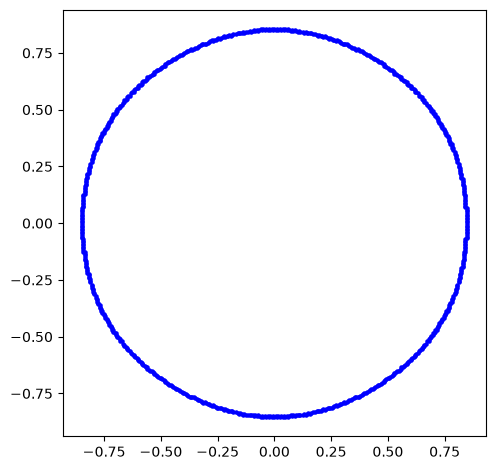

In [5]:
# Plot calculated Fermi contour in 2D

fig, ax = plt.subplots()
for k_value in fermi_contour:
    ax.scatter(k_value[0], k_value[1], s = 5, color = "blue")
ax.set_aspect("equal")
plt.tight_layout()
plt.savefig(f"../../imgs/fermi_contours/{filename}.jpg")
plt.show()

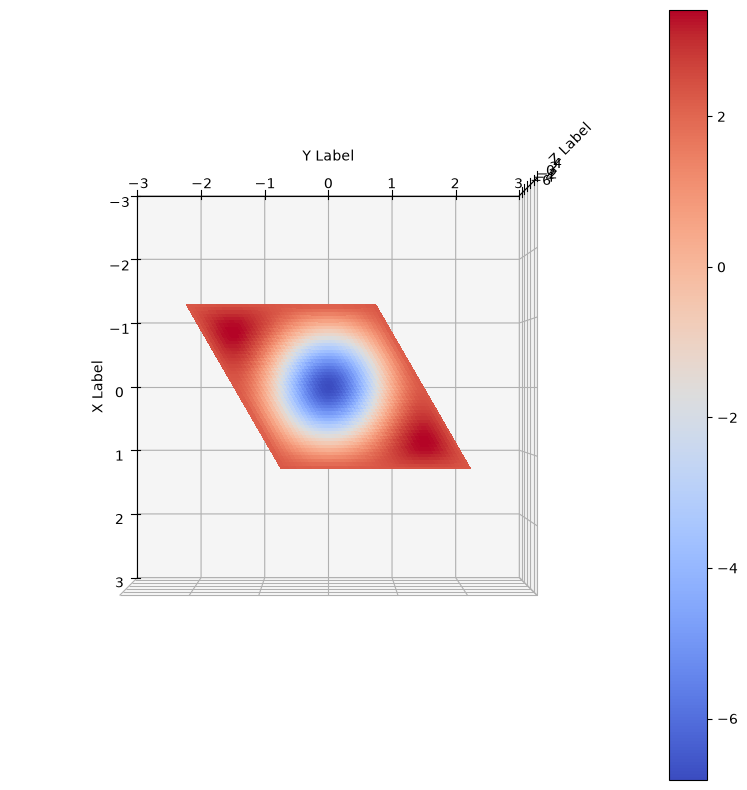

In [6]:
# Visualize 3D energy band structure

energy_band = np.array(energy_band)
energy_band = energy_band.reshape(N_monkhorst,N_monkhorst)

kx_mesh = ks[0].reshape(N_monkhorst,N_monkhorst)
ky_mesh = ks[1].reshape(N_monkhorst,N_monkhorst)

fig = plt.figure(figsize=[10,10])
ax = fig.add_subplot(projection='3d')

plot1 = ax.plot_surface(kx_mesh, ky_mesh, energy_band, cmap=cm.coolwarm, linewidth=3, antialiased=False)
fermi_arr = np.array(fermi_contour)
ax.scatter(fermi_arr[:, 0], fermi_arr[:, 1], len(fermi_arr[:,1])*[2.5], color="black", s=1, label="Fermi contour")

ax.set_xlim3d(-3,3)
ax.set_ylim3d(-3,3)

ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')

ax.view_init(elev=90, azim=0)
plt.colorbar(plot1)

plt.show()